# Portfolio Downside Risk & Tail Analytics — Quantamental AI

**Module:** Portfolio Engine — Phase 2 Research Layer  
**Notebook:** `07_risk_metrics_analysis.ipynb`  
**Market:** National Stock Exchange of India (NSE)  
**Universe:** 10-Stock Blue-Chip Large-Cap Equities  
**Standards:** J.P. Morgan RiskMetrics (1996), Cornish & Fisher (1937), Artzner et al. (1999), Rockafellar & Uryasev (2000, 2002)

---

## Executive Summary & Educational Objectives

In classical Mean-Variance Optimization (Markowitz, 1952), portfolio risk is modeled strictly by second-moment variance ($\sigma^2$), implicitly assuming that returns follow a symmetric Gaussian distribution. In actual equity markets—and specifically in the Indian equity market (NSE)—asset return distributions exhibit pronounced **negative skewness** (asymmetric left-tail shocks) and **leptokurtosis** (fat tails with high kurtosis, $K > 3$).

This research notebook delivers an end-to-end empirical and theoretical investigation of portfolio downside risk using actual historical NSE daily data. All computations are powered exclusively by the production backend module `backend/app/portfolio_engine/risk_metrics.py`.

### Learning Objectives:
1. **Value at Risk (VaR)**: Contrast Parametric (Gaussian), Historical (Non-Parametric empirical quantile), and Modified Cornish-Fisher (skewness/kurtosis adjusted) VaR at 95% and 99% confidence levels.
2. **Conditional Value at Risk (CVaR / Expected Shortfall)**: Understand why VaR is not a coherent risk measure (failing subadditivity) and how CVaR quantifies the average severity of losses beyond the VaR threshold.
3. **Cornish-Fisher Expansion Mechanics**: Unpack how empirical asymmetry ($S$) and tail thickness ($K$) modify the standard Gaussian critical values ($z_\alpha \to \tilde{z}_\alpha$).
4. **Diversification & Tail Risk Subadditivity**: Quantify how equal-weight multi-asset allocation reduces portfolio tail risk relative to individual asset constituents.
5. **Dynamic Rolling Risk**: Analyze 252-day rolling downside metrics to observe volatility clustering and market stress regimes.

### Sign Convention:
Per the approved project financial methodology:
$$\text{Positive values represent potential losses; negative values represent gains.}$$
A daily 95% VaR of $+1.35\%$ denotes that a loss exceeding $1.35\%$ occurs with a probability of $5\%$ (1 in 20 trading sessions).


---
## 1. Environment Setup & Project Path Discovery

This notebook automatically discovers the repository root and adds `backend/` to `sys.path`. This enables direct import of production modules without fragile hardcoded paths, supporting both local execution and Google Colab environments.


In [1]:
import os
import sys
from pathlib import Path

# Auto-detect repository root
def find_repo_root() -> Path:
    current = Path.cwd().resolve()
    for candidate in [current] + list(current.parents):
        if (candidate / 'backend' / 'app').is_dir():
            return candidate
    colab_candidate = Path(os.environ.get('COLAB_REPO_ROOT', '/content/Quantamental_AI'))
    if (colab_candidate / 'backend' / 'app').is_dir():
        return colab_candidate
    raise RuntimeError("Could not locate repository root containing 'backend/app'.")

REPO_ROOT = find_repo_root()
BACKEND_DIR = REPO_ROOT / 'backend'

if str(BACKEND_DIR) not in sys.path:
    sys.path.insert(0, str(BACKEND_DIR))

print(f"Repository root : {REPO_ROOT}")
print(f"Backend path    : {BACKEND_DIR}")
print(f"Backend exists  : {BACKEND_DIR.is_dir()}")


Repository root : /Users/lakshyabapna/Desktop/Quantamental_AI
Backend path    : /Users/lakshyabapna/Desktop/Quantamental_AI/backend
Backend exists  : True


In [2]:
# Dependency check for Google Colab or fresh virtual environment
try:
    import yfinance
    import matplotlib
    import seaborn
    import scipy
except ImportError:
    print("Installing required quantitative dependencies...")
    !pip install -q yfinance matplotlib seaborn scipy scikit-learn pandas numpy

print("All required external packages are present.")


All required external packages are present.


### Standard Library & Quantitative Imports

We configure reproducible seeds, statistical libraries, and visualization defaults.


In [3]:
import time
import zoneinfo
import warnings
from datetime import datetime, date, time as dtime, timedelta
from typing import Dict, List, Tuple, Optional, Any

import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=UserWarning)

# Visualization styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Helvetica']
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8

# Reproducibility seed
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

print("Quantitative and plotting environments successfully initialized.")


Quantitative and plotting environments successfully initialized.


---
## 2. Production Backend Imports

All financial and mathematical calculations are delegated **exclusively** to the production backend modules. No financial algorithms are reimplemented in notebook cells.


In [4]:
# Production NSE Trading Calendar
from app.data_engine.calendar import nse_calendar

# Returns engine (Phase 2.1)
from app.portfolio_engine.returns import (
    calculate_simple_returns,
    calculate_expected_returns,
)

# Downside and Tail Risk Analytics Engine (Phase 2 Task 7)
from app.portfolio_engine.risk_metrics import (
    RiskMetricsEngine,
    RiskMetricsResult,
    CornishFisherExpansionResult,
    calculate_risk_metrics,
    calculate_historical_var,
    calculate_parametric_var,
    calculate_cornish_fisher_var,
    calculate_cvar,
    calculate_cornish_fisher_expansion,
)

# Canonical domain exceptions
from app.core.exceptions import (
    FinancialCalculationError,
    InsufficientDataError,
)

print("✓ All Quantamental AI production backend modules imported successfully.")


✓ All Quantamental AI production backend modules imported successfully.


---
## 3. Investment Universe & Production NSE Trading Calendar

We evaluate the canonical 10-stock blue-chip universe from the National Stock Exchange of India (NSE).

### NSE Trading Calendar Integration
To prevent look-ahead bias and data leakage:
1. Dates are evaluated in Indian Standard Time (`Asia/Kolkata`).
2. If the current time is on a trading weekday $\ge$ 16:00 IST (after closing auctions settle), today's session is treated as the latest completed session.
3. If evaluated before 16:00 IST or on a weekend/exchange holiday, the date rolls back to the latest confirmed completed session via `nse_calendar.get_previous_trading_day()`.
4. Rolling 5-year start date is resolved via `nse_calendar.get_rolling_window_start(END_DATE, years=5)`.

### Methodological Limitation — Survivorship Bias
This analysis evaluates the current selected 10-stock NSE universe over historical data. It does not reconstruct historical point-in-time universe membership or index constituents. Consequently, historical findings may contain survivorship bias (reflecting companies that remained prominent, solvent, and liquid through 2026) and must not be interpreted as an unbiased estimate of historical broad-market universe performance.


In [5]:
# ---------------------------------------------------------------------------
# Investment Universe: 10 Blue-Chip NSE Equities
# ---------------------------------------------------------------------------
TICKERS = [
    'RELIANCE.NS',
    'TCS.NS',
    'HDFCBANK.NS',
    'ICICIBANK.NS',
    'INFY.NS',
    'HINDUNILVR.NS',
    'LT.NS',
    'ITC.NS',
    'BHARTIARTL.NS',
    'MARUTI.NS',
]

TICKER_LABELS = {
    'RELIANCE.NS': 'Reliance',
    'TCS.NS': 'TCS',
    'HDFCBANK.NS': 'HDFC Bank',
    'ICICIBANK.NS': 'ICICI Bank',
    'INFY.NS': 'Infosys',
    'HINDUNILVR.NS': 'HUL',
    'LT.NS': 'L&T',
    'ITC.NS': 'ITC',
    'BHARTIARTL.NS': 'Airtel',
    'MARUTI.NS': 'Maruti',
}

# Determine latest completed NSE trading session in Asia/Kolkata
def get_latest_completed_nse_session(as_of_dt: Optional[datetime] = None) -> date:
    IST = zoneinfo.ZoneInfo("Asia/Kolkata")
    dt = datetime.now(IST) if as_of_dt is None else (as_of_dt.astimezone(IST) if as_of_dt.tzinfo else as_of_dt.replace(tzinfo=IST))
    today_date = dt.date()
    NSE_CLOSE_TIME = dtime(16, 0)
    
    if nse_calendar.is_trading_day(today_date):
        return today_date if dt.time() >= NSE_CLOSE_TIME else nse_calendar.get_previous_trading_day(today_date)
    else:
        return nse_calendar.get_previous_trading_day(today_date)

# Calendar regression test suite
IST = zoneinfo.ZoneInfo("Asia/Kolkata")
cal_reg_sat  = get_latest_completed_nse_session(datetime(2026, 1, 24, 12, 0, tzinfo=IST))
cal_reg_sun  = get_latest_completed_nse_session(datetime(2026, 1, 25, 18, 0, tzinfo=IST))
cal_reg_hol  = get_latest_completed_nse_session(datetime(2026, 1, 26, 17, 0, tzinfo=IST))
cal_reg_pre  = get_latest_completed_nse_session(datetime(2026, 1, 27, 15, 0, tzinfo=IST))
cal_reg_post = get_latest_completed_nse_session(datetime(2026, 1, 27, 16, 15, tzinfo=IST))

assert cal_reg_sat == date(2026, 1, 23), "Saturday check failed"
assert cal_reg_sun == date(2026, 1, 23), "Sunday check failed"
assert cal_reg_hol == date(2026, 1, 23), "Holiday check failed"
assert cal_reg_pre == date(2026, 1, 23), "Pre-16:00 check failed"
assert cal_reg_post == date(2026, 1, 27), "Post-16:00 check failed"

INTENDED_END_DATE = get_latest_completed_nse_session()
START_DATE        = nse_calendar.get_rolling_window_start(INTENDED_END_DATE, years=5)
END_DATE          = INTENDED_END_DATE

# Project Constants
TRADING_DAYS_PER_YEAR = 252
CONFIDENCE_LEVELS     = (0.95, 0.99)

print(f"Universe         : {len(TICKERS)} stocks")
print(f"Data window      : {START_DATE} → {INTENDED_END_DATE} (intended completed session)")
print(f"Confidence levels: {CONFIDENCE_LEVELS}")
print("✓ Calendar regression checks verified across weekends, holidays, and intraday cutoffs.")


Universe         : 10 stocks
Data window      : 2021-11-23 → 2026-11-23 (intended completed session)
Confidence levels: (0.95, 0.99)
✓ Calendar regression checks verified across weekends, holidays, and intraday cutoffs.


---
## 4. Historical Data Acquisition & Observation Verification

We retrieve adjusted closing price data using `yfinance.download(auto_adjust=True)`. Missing price dates are preserved to ensure daily simple returns do not stitch discontinuous dates into synthetic multi-session jumps.


In [6]:
import yfinance as yf

print(f"Downloading historical adjusted price data for {len(TICKERS)} tickers...")
print(f"Target Period: {START_DATE} → {INTENDED_END_DATE}")

try:
    raw_prices = yf.download(
        tickers=TICKERS,
        start=START_DATE.isoformat(),
        end=(INTENDED_END_DATE + timedelta(days=1)).isoformat(),
        auto_adjust=True,
        progress=False,
    )
except Exception as exc:
    raise RuntimeError(f"Failed to fetch market data: {exc}") from exc

if raw_prices is None or raw_prices.empty:
    raise RuntimeError("Downloaded market price DataFrame is empty.")

if isinstance(raw_prices.columns, pd.MultiIndex):
    prices = raw_prices['Close'].copy()
else:
    prices = raw_prices[['Close']].copy()

prices.index = pd.to_datetime(prices.index).normalize()
prices.index.name = 'Date'

# Enforce intended observation cutoff
prices = prices[prices.index.date <= INTENDED_END_DATE]

actual_latest_session = prices.index[-1].date()
if actual_latest_session == INTENDED_END_DATE:
    print(f"✓ Download verified: latest observation matches intended completed session ({INTENDED_END_DATE}).")
else:
    print(f"⚠ Notice: intended session was {INTENDED_END_DATE}, but latest feed observation is {actual_latest_session}.")
    print(f"  Setting active window cutoff to actual completed session: {actual_latest_session}.")

END_DATE = actual_latest_session

print(f"Downloaded prices shape: {prices.shape} (rows × assets)")
print(f"Date range             : {prices.index[0].date()} → {prices.index[-1].date()}")
prices.tail(3)


Target Period: 2021-11-23 → 2026-11-23


✓ Download verified: latest observation matches intended completed session (2026-11-23).
Downloaded prices shape: (1237, 10) (rows × assets)
Date range             : 2021-11-23 → 2026-11-23


Ticker,BHARTIARTL.NS,HDFCBANK.NS,HINDUNILVR.NS,ICICIBANK.NS,INFY.NS,ITC.NS,LT.NS,MARUTI.NS,RELIANCE.NS,TCS.NS
Date,,,,,,,,,,
2026-11-19,2144.000000,821.799988,2074.199951,1608.900024,1091.900024,301.000000,4211.000000,13589.0,1375.599976,2342.699951
2026-11-20,2161.699951,846.000000,2052.500000,1640.000000,1098.000000,299.100006,4209.100098,14011.0,1377.500000,2376.199951
2026-11-23,2128.500000,817.799988,2019.099976,1585.500000,1103.400024,301.000000,4099.899902,14010.0,1351.000000,2460.000000


In [7]:
# Data quality validation
total_rows = len(prices)
quality_df = pd.DataFrame({
    'Missing Count': prices.isna().sum(),
    'Missing %'    : (prices.isna().sum() / total_rows * 100).round(2),
    'Valid Count'  : prices.notna().sum(),
    'Min Price'    : prices.min().round(2),
    'Max Price'    : prices.max().round(2),
    'Last Price'   : prices.iloc[-1].round(2),
}).rename(index=TICKER_LABELS)

print(f"Total downloaded trading sessions: {total_rows}")
print()
print(quality_df.to_string())

non_positive = (prices <= 0).sum()
if non_positive.any():
    raise ValueError(f"Non-positive prices detected: {non_positive[non_positive > 0]}")
print("\n✓ No non-positive prices detected. Physical asset price viability confirmed.")


Total downloaded trading sessions: 1237

            Missing Count  Missing %  Valid Count  Min Price  Max Price  Last Price
Ticker                                                                             
Airtel                  0        0.0         1237     618.60    2161.70      2128.5
HDFC Bank               0        0.0         1237     606.49     996.42       817.8
HUL                     0        0.0         1237    1776.58    2882.52      2019.1
ICICI Bank              0        0.0         1237     628.85    1640.00      1585.5
Infosys                 0        0.0         1237     963.23    1858.51      1103.4
ITC                     0        0.0         1237     166.77     463.95       301.0
L&T                     0        0.0         1237    1398.80    4375.36      4099.9
Maruti                  0        0.0         1237    6464.16   17120.06     14010.0
Reliance                0        0.0         1237    1000.24    1584.97      1351.0
TCS                     0        0.

---
## 5. Daily Simple Returns & Equal-Weight Portfolio Construction

### Financial Methodology Standards:
1. **Daily Simple Returns**:
   $$R_{i,t} = \frac{P_{i,t}}{P_{i,t-1}} - 1$$
   Calculated directly on un-dropped prices using production `calculate_simple_returns()`. Missing-session gaps produce `NaN` and are discarded under listwise-complete filtering (`aligned=True`) across assets, preventing synthetic multi-session jumps.
2. **Equal-Weight Portfolio ($w_i = 1/N$)**:
   An illustrative benchmark portfolio representing diversified exposure across the 10 large-cap equities:
   $$R_{p, t} = \sum_{i=1}^{N} w_i R_{i, t} = \mathbf{w}^T \mathbf{R}_t$$


In [8]:
# Step 1: Calculate daily simple returns using production module
returns = calculate_simple_returns(prices=prices, aligned=True)
assert isinstance(returns, pd.DataFrame), "Expected DataFrame of aligned returns"
T_obs, N_assets = returns.shape
print(f"Aligned daily simple returns: {T_obs} sessions × {N_assets} assets")

# Synthetic gap safety check: verify intermediate NaN does not bridge into synthetic return
synth_prices = pd.DataFrame({'TEST': [100.0, np.nan, 105.0]}, index=pd.date_range('2026-01-01', periods=3))
synth_returns = calculate_simple_returns(synth_prices, aligned=False)
assert pd.isna(synth_returns['TEST'].iloc[0]), "Return on missing date must be NaN"
assert pd.isna(synth_returns['TEST'].iloc[1]), "Return after missing date must be NaN (no synthetic stitching)"
print("✓ Missing-price return safety verified: no synthetic returns across missing sessions.")

# Step 2: Construct illustrative Equal-Weight Portfolio (w_i = 1/10)
equal_weights = pd.Series(1.0 / N_assets, index=returns.columns, name="weight")
portfolio_returns: pd.Series = returns.dot(equal_weights)
portfolio_returns.name = "Equal_Weight_Portfolio"

ann_mean = portfolio_returns.mean() * TRADING_DAYS_PER_YEAR
ann_vol  = portfolio_returns.std() * np.sqrt(TRADING_DAYS_PER_YEAR)
sharpe   = (ann_mean - 0.065) / ann_vol

print(f"\nEqual-Weight Portfolio Summary (T={len(portfolio_returns)} days):")
print(f"  Annualised Arithmetic Return : {ann_mean:.2%}")
print(f"  Annualised Volatility (σ)    : {ann_vol:.2%}")
print(f"  Annualised Sharpe (rf=6.5%)  : {sharpe:.4f}")
print(f"  Daily Return Mean            : {portfolio_returns.mean():.6f}")
print(f"  Daily Return Std Dev         : {portfolio_returns.std():.6f}")
print(f"  Daily Return Min (Worst Day) : {portfolio_returns.min():.2%}")
print(f"  Daily Return Max (Best Day)  : {portfolio_returns.max():.2%}")


Aligned daily simple returns: 1236 sessions × 10 assets
✓ Missing-price return safety verified: no synthetic returns across missing sessions.

Equal-Weight Portfolio Summary (T=1236 days):
  Annualised Arithmetic Return : 9.83%
  Annualised Volatility (σ)    : 13.43%
  Annualised Sharpe (rf=6.5%)  : 0.2479
  Daily Return Mean            : 0.000390
  Daily Return Std Dev         : 0.008463
  Daily Return Min (Worst Day) : -4.49%
  Daily Return Max (Best Day)  : 3.86%


---
## 6. Mathematical Methodology: Downside & Tail Risk Analytics

### 6.1 Value at Risk (VaR)
Value at Risk measures the quantile-based loss threshold over a 1-day horizon at confidence level $c = 1 - \alpha$. Under the positive loss convention:
$$\mathbb{P}(R_t \le -\text{VaR}_\alpha) = \alpha$$

#### 6.1.1 Parametric VaR (Gaussian Assumption)
Assumes returns follow a normal distribution $\mathcal{N}(\mu, \sigma^2)$:
$$\text{VaR}_\alpha^{\text{param}} = - (\mu + z_\alpha \sigma)$$
where $z_{0.05} = -1.64485$ (95% confidence) and $z_{0.01} = -2.32635$ (99% confidence).

#### 6.1.2 Historical VaR (Empirical Quantile)
Computes the empirical $\alpha$-quantile without parametric distribution assumptions:
$$\text{VaR}_\alpha^{\text{hist}} = - \text{Quantile}_\alpha(\{R_1, \dots, R_T\})$$

#### 6.1.3 Modified Cornish-Fisher VaR (Higher-Moment Expansion)
Adjusts standard Gaussian quantiles using Fisher's expansion for empirical skewness ($S$) and excess kurtosis ($K$):
$$\tilde{z}_\alpha = z_\alpha + \underbrace{\frac{1}{6}(z_\alpha^2 - 1)S}_{\text{Skewness Linear Term}} + \underbrace{\frac{1}{24}(z_\alpha^3 - 3z_\alpha)K}_{\text{Kurtosis Term}} - \underbrace{\frac{1}{36}(2z_\alpha^3 - 5z_\alpha)S^2}_{\text{Skewness Quadratic Term}}$$
$$\text{VaR}_\alpha^{\text{CF}} = - (\mu + \tilde{z}_\alpha \sigma)$$

### 6.2 Conditional Value at Risk (CVaR / Expected Shortfall)
CVaR measures the expected loss conditional on the loss exceeding the VaR threshold:
$$\text{CVaR}_\alpha = - \mathbb{E}[R_t \mid R_t \le -\text{VaR}_\alpha] = - \frac{1}{\sum_{t=1}^T \mathbb{I}(R_t \le -\text{VaR}_\alpha)} \sum_{t: R_t \le -\text{VaR}_\alpha} R_t$$

**Theoretical Invariants & Coherence:**
1. **Threshold Lower Bound:** By definition, the conditional mean of tail losses cannot be less severe than the threshold:
   $$\text{CVaR}_\alpha \ge \text{VaR}_\alpha^{\text{hist}}$$
2. **Subadditivity (Coherent Risk Measure):** Unlike VaR, CVaR is a coherent risk measure (Artzner et al., 1999). Under the coherent Expected Shortfall definition, portfolio CVaR is mathematically guaranteed to be no greater than the weighted sum of constituent CVaRs:
   $$\text{CVaR}_\alpha(\mathbf{w}^T \mathbf{R}) \le \sum_{i=1}^N w_i \text{CVaR}_\alpha(R_i)$$
   This theoretical property establishes that portfolio risk is bounded above by constituent risk; while comonotonic assets achieve equality ($\text{CVaR}_p = \sum w_i \text{CVaR}_i$), imperfectly correlated assets yield the strict inequality ($\text{CVaR}_p < \sum w_i \text{CVaR}_i$) observed in our empirical dataset.


In [9]:
# ---------------------------------------------------------------------------
# Downside Risk Evaluation via Production Engine
# ---------------------------------------------------------------------------

# 1. Object-Oriented Engine (RiskMetricsEngine)
engine = RiskMetricsEngine(bias=False, method='linear')
oop_result: RiskMetricsResult = engine.calculate(portfolio_returns, confidence_levels=CONFIDENCE_LEVELS)

# 2. Functional API (calculate_risk_metrics)
func_result: RiskMetricsResult = calculate_risk_metrics(portfolio_returns, confidence_levels=CONFIDENCE_LEVELS)

# 3. Verify exact numerical equivalence between OOP and Functional interfaces
assert np.isclose(oop_result.parametric_var_95, func_result.parametric_var_95, atol=1e-12)
assert np.isclose(oop_result.historical_var_95, func_result.historical_var_95, atol=1e-12)
assert np.isclose(oop_result.cornish_fisher_var_95, func_result.cornish_fisher_var_95, atol=1e-12)
assert np.isclose(oop_result.cvar_95, func_result.cvar_95, atol=1e-12)
assert np.isclose(oop_result.parametric_var_99, func_result.parametric_var_99, atol=1e-12)
assert np.isclose(oop_result.historical_var_99, func_result.historical_var_99, atol=1e-12)
assert np.isclose(oop_result.cornish_fisher_var_99, func_result.cornish_fisher_var_99, atol=1e-12)
assert np.isclose(oop_result.cvar_99, func_result.cvar_99, atol=1e-12)

print("✓ Numerical equivalence between RiskMetricsEngine and calculate_risk_metrics confirmed.")
print(f"Sample size evaluated: T = {oop_result.sample_size} sessions")


✓ Numerical equivalence between RiskMetricsEngine and calculate_risk_metrics confirmed.
Sample size evaluated: T = 1236 sessions


In [10]:
# Format portfolio results into clear presentation table
port_metrics_df = pd.DataFrame([
    {
        'Metric': 'Parametric VaR (Gaussian)',
        '95% Confidence (1-day)': f"{oop_result.parametric_var_95:.4%}",
        '99% Confidence (1-day)': f"{oop_result.parametric_var_99:.4%}",
        'Methodology / Assumptions': 'Normality assumed: μ + z_α σ'
    },
    {
        'Metric': 'Historical VaR (Empirical)',
        '95% Confidence (1-day)': f"{oop_result.historical_var_95:.4%}",
        '99% Confidence (1-day)': f"{oop_result.historical_var_99:.4%}",
        'Methodology / Assumptions': 'Non-parametric: -Quantile_α(R)'
    },
    {
        'Metric': 'Cornish-Fisher VaR (Modified)',
        '95% Confidence (1-day)': f"{oop_result.cornish_fisher_var_95:.4%}",
        '99% Confidence (1-day)': f"{oop_result.cornish_fisher_var_99:.4%}",
        'Methodology / Assumptions': 'Higher-order expansion: μ + z̃_α σ'
    },
    {
        'Metric': 'Conditional VaR (Expected Shortfall)',
        '95% Confidence (1-day)': f"{oop_result.cvar_95:.4%}",
        '99% Confidence (1-day)': f"{oop_result.cvar_99:.4%}",
        'Methodology / Assumptions': 'Expected tail loss: E[-R | R ≤ -VaR]'
    },
])

print("================================================================================")
print("Equal-Weight Portfolio Downside Risk Metrics (Daily Horizon)")
print("================================================================================")
print(port_metrics_df.to_string(index=False))
print()
print("Distribution Higher Moments:")
print(f"  Daily Mean Return        : {oop_result.mean_return:+.6f} ({oop_result.mean_return * TRADING_DAYS_PER_YEAR:+.2%} p.a.)")
print(f"  Daily Volatility (σ)     : {oop_result.volatility:.6f} ({oop_result.volatility * np.sqrt(TRADING_DAYS_PER_YEAR):.2%} p.a.)")
print(f"  Empirical Skewness (S)   : {oop_result.skewness:+.4f} (Negative: left-tail skew)")
print(f"  Excess Kurtosis (K)      : {oop_result.excess_kurtosis:+.4f} (Leptokurtic fat tails: K > 0)")

# Decompose Cornish-Fisher expansion terms
cf_95_details = oop_result.details['by_confidence_level']['95%']['cornish_fisher_expansion']
cf_99_details = oop_result.details['by_confidence_level']['99%']['cornish_fisher_expansion']

cf_decomp_df = pd.DataFrame([
    {
        'Confidence Level': '95% (α = 0.05)',
        'Gaussian z_α': f"{cf_95_details['standard_z']:.4f}",
        'Skewness Linear': f"{cf_95_details['skewness_linear_term']:+.4f}",
        'Kurtosis Term': f"{cf_95_details['kurtosis_term']:+.4f}",
        'Skewness Quadratic': f"{cf_95_details['skewness_quadratic_term']:+.4f}",
        'Adjusted z̃_α': f"{cf_95_details['adjusted_z']:.4f}",
    },
    {
        'Confidence Level': '99% (α = 0.01)',
        'Gaussian z_α': f"{cf_99_details['standard_z']:.4f}",
        'Skewness Linear': f"{cf_99_details['skewness_linear_term']:+.4f}",
        'Kurtosis Term': f"{cf_99_details['kurtosis_term']:+.4f}",
        'Skewness Quadratic': f"{cf_99_details['skewness_quadratic_term']:+.4f}",
        'Adjusted z̃_α': f"{cf_99_details['adjusted_z']:.4f}",
    },
])
print("\nCornish-Fisher Expansion Term Decomposition:")
print(cf_decomp_df.to_string(index=False))


Equal-Weight Portfolio Downside Risk Metrics (Daily Horizon)
                              Metric 95% Confidence (1-day) 99% Confidence (1-day)            Methodology / Assumptions
           Parametric VaR (Gaussian)                1.3530%                1.9298%         Normality assumed: μ + z_α σ
          Historical VaR (Empirical)                1.3171%                2.1723%       Non-parametric: -Quantile_α(R)
       Cornish-Fisher VaR (Modified)                1.3367%                2.3475%   Higher-order expansion: μ + z̃_α σ
Conditional VaR (Expected Shortfall)                1.8420%                2.7462% Expected tail loss: E[-R | R ≤ -VaR]

Distribution Higher Moments:
  Daily Mean Return        : +0.000390 (+9.83% p.a.)
  Daily Volatility (σ)     : 0.008463 (13.43% p.a.)
  Empirical Skewness (S)   : -0.0677 (Negative: left-tail skew)
  Excess Kurtosis (K)      : +1.9056 (Leptokurtic fat tails: K > 0)

Cornish-Fisher Expansion Term Decomposition:
Confidence Level Gaussian 

---
## 7. Individual Asset vs. Portfolio Downside Risk Analysis

We compute risk metrics across all 10 individual equities and compare them to the equal-weight portfolio. This demonstrates the **diversification effect** on downside tail risk.


In [11]:
asset_results = {}
asset_rows = []

for ticker in TICKERS:
    r_series = returns[ticker]
    res: RiskMetricsResult = engine.calculate(r_series, confidence_levels=CONFIDENCE_LEVELS)
    asset_results[ticker] = res
    
    asset_rows.append({
        'Ticker': ticker,
        'Name': TICKER_LABELS[ticker],
        'Ann Return': f"{res.mean_return * TRADING_DAYS_PER_YEAR:+.2%}",
        'Ann Vol': f"{res.volatility * np.sqrt(TRADING_DAYS_PER_YEAR):.2%}",
        'Skewness': f"{res.skewness:+.2f}",
        'Excess Kurt': f"{res.excess_kurtosis:+.2f}",
        'Hist VaR 95%': f"{res.historical_var_95:.2%}",
        'Param VaR 95%': f"{res.parametric_var_95:.2%}",
        'CF VaR 95%': f"{res.cornish_fisher_var_95:.2%}",
        'CVaR 95%': f"{res.cvar_95:.2%}",
        'Hist VaR 99%': f"{res.historical_var_99:.2%}",
        'CVaR 99%': f"{res.cvar_99:.2%}",
    })

# Append Portfolio Row
asset_rows.append({
    'Ticker': 'PORTFOLIO',
    'Name': 'Equal Weight (10 Stocks)',
    'Ann Return': f"{oop_result.mean_return * TRADING_DAYS_PER_YEAR:+.2%}",
    'Ann Vol': f"{oop_result.volatility * np.sqrt(TRADING_DAYS_PER_YEAR):.2%}",
    'Skewness': f"{oop_result.skewness:+.2f}",
    'Excess Kurt': f"{oop_result.excess_kurtosis:+.2f}",
    'Hist VaR 95%': f"{oop_result.historical_var_95:.2%}",
    'Param VaR 95%': f"{oop_result.parametric_var_95:.2%}",
    'CF VaR 95%': f"{oop_result.cornish_fisher_var_95:.2%}",
    'CVaR 95%': f"{oop_result.cvar_95:.2%}",
    'Hist VaR 99%': f"{oop_result.historical_var_99:.2%}",
    'CVaR 99%': f"{oop_result.cvar_99:.2%}",
})

asset_comparison_df = pd.DataFrame(asset_rows)
print("Downside Risk Comparison: Individual Constituents vs. Equal-Weight Portfolio")
print(asset_comparison_df.to_string(index=False))


Downside Risk Comparison: Individual Constituents vs. Equal-Weight Portfolio
       Ticker                     Name Ann Return Ann Vol Skewness Excess Kurt Hist VaR 95% Param VaR 95% CF VaR 95% CVaR 95% Hist VaR 99% CVaR 99%
  RELIANCE.NS                 Reliance     +7.14%  22.80%    +0.52       +5.56        2.12%         2.33%      1.96%    3.02%        3.36%    4.48%
       TCS.NS                      TCS     -1.40%  22.97%    +0.11       +3.44        2.11%         2.39%      2.24%    3.27%        3.86%    4.96%
  HDFCBANK.NS                HDFC Bank     +5.18%  21.31%    -0.07       +5.28        2.09%         2.19%      2.07%    3.14%        3.62%    5.00%
 ICICIBANK.NS               ICICI Bank    +17.98%  19.87%    -0.05       +2.73        1.85%         1.99%      1.94%    2.70%        3.22%    4.26%
      INFY.NS                  Infosys     -2.67%  26.36%    -0.16       +3.29        2.61%         2.74%      2.71%    3.81%        4.31%    6.20%
HINDUNILVR.NS                      

In [12]:
# Quantify Diversification Benefit
weighted_avg_hvar_95 = sum(asset_results[t].historical_var_95 * (1.0 / len(TICKERS)) for t in TICKERS)
weighted_avg_cvar_95 = sum(asset_results[t].cvar_95 * (1.0 / len(TICKERS)) for t in TICKERS)
port_hvar_95 = oop_result.historical_var_95
port_cvar_95 = oop_result.cvar_95

var_div_pct = (1.0 - (port_hvar_95 / weighted_avg_hvar_95)) * 100
cvar_div_pct = (1.0 - (port_cvar_95 / weighted_avg_cvar_95)) * 100

print("================================================================================")
print("Diversification Benefit on Downside Tail Risk (Subadditivity)")
print("================================================================================")
print(f"Weighted Average Asset 95% Historical VaR : {weighted_avg_hvar_95:.4%}")
print(f"Equal-Weight Portfolio 95% Historical VaR  : {port_hvar_95:.4%}")
print(f"Tail Risk Reduction via Diversification    : {var_div_pct:.2f}%")
print()
print(f"Weighted Average Asset 95% CVaR           : {weighted_avg_cvar_95:.4%}")
print(f"Equal-Weight Portfolio 95% CVaR            : {port_cvar_95:.4%}")
print(f"Tail Severity Reduction via Diversification: {cvar_div_pct:.2f}%")
print()
# Under coherent risk measures, subadditivity guarantees CVaR_p <= sum(w_i * CVaR_i).
# For our imperfectly correlated 10-stock NSE universe, we observe strict inequality (CVaR_p < sum(w_i * CVaR_i)).
assert port_hvar_95 < weighted_avg_hvar_95, "Portfolio VaR must be strictly less than weighted average asset VaR for this dataset"
assert port_cvar_95 < weighted_avg_cvar_95, "Portfolio CVaR must be strictly less than weighted average asset CVaR for this dataset"
print("✓ Empirical subadditivity and diversification benefit confirmed for this dataset.")



Diversification Benefit on Downside Tail Risk (Subadditivity)
Weighted Average Asset 95% Historical VaR : 2.0757%
Equal-Weight Portfolio 95% Historical VaR  : 1.3171%
Tail Risk Reduction via Diversification    : 36.55%

Weighted Average Asset 95% CVaR           : 3.1020%
Equal-Weight Portfolio 95% CVaR            : 1.8420%
Tail Severity Reduction via Diversification: 40.62%

✓ Empirical subadditivity and diversification benefit confirmed for this dataset.


---
## 8. Rolling Downside Risk & Market Regime Dynamics

Financial risk is not static. Volatility clusters (Mandelbrot, 1963; Engle, 1982) and tail risk expands during market turbulence. We evaluate 252-trading-day (1-year) rolling risk metrics across time using the production engine.


In [13]:
# 252-day rolling window risk calculation
window_size = 252
rolling_dates = []
rolling_hvar_95 = []
rolling_cfvar_95 = []
rolling_cvar_95 = []
rolling_ann_vol = []

print(f"Calculating rolling downside risk metrics (window={window_size} sessions)...")
for end_idx in range(window_size, len(portfolio_returns) + 1):
    sub_returns = portfolio_returns.iloc[end_idx - window_size : end_idx]
    current_date = sub_returns.index[-1]
    
    # Calculate using production RiskMetricsEngine
    hvar = engine.historical_var(sub_returns, confidence_level=0.95)
    cfvar = engine.cornish_fisher_var(sub_returns, confidence_level=0.95)
    cvar = engine.cvar(sub_returns, confidence_level=0.95)
    ann_vol = sub_returns.std() * np.sqrt(TRADING_DAYS_PER_YEAR)
    
    rolling_dates.append(current_date)
    rolling_hvar_95.append(hvar)
    rolling_cfvar_95.append(cfvar)
    rolling_cvar_95.append(cvar)
    rolling_ann_vol.append(ann_vol)

rolling_df = pd.DataFrame({
    'Historical_VaR_95': rolling_hvar_95,
    'Cornish_Fisher_VaR_95': rolling_cfvar_95,
    'CVaR_95': rolling_cvar_95,
    'Annualised_Vol': rolling_ann_vol,
}, index=pd.DatetimeIndex(rolling_dates))

print(f"✓ Rolling analysis complete: {len(rolling_df)} rolling windows computed.")
print(f"  Historical VaR 95% range: {rolling_df['Historical_VaR_95'].min():.2%} → {rolling_df['Historical_VaR_95'].max():.2%}")
print(f"  CVaR 95% range          : {rolling_df['CVaR_95'].min():.2%} → {rolling_df['CVaR_95'].max():.2%}")


Calculating rolling downside risk metrics (window=252 sessions)...


✓ Rolling analysis complete: 985 rolling windows computed.
  Historical VaR 95% range: 0.83% → 1.73%
  CVaR 95% range          : 1.13% → 2.31%


---
## 9. Comprehensive Downside Risk Visualizations

We generate five high-resolution, institutional-grade visualizations analyzing portfolio and asset tail risk:
1. **Portfolio Return Distribution with VaR & CVaR Thresholds**
2. **VaR Methodology Comparison (Parametric vs. Historical vs. Cornish-Fisher vs. CVaR)**
3. **Tail Severity Beyond VaR ($\Delta = \text{CVaR} - \text{VaR}$)**
4. **Individual Asset vs. Portfolio Downside Risk Ranking**
5. **Rolling 252-Day Downside Risk & Volatility Dynamics**


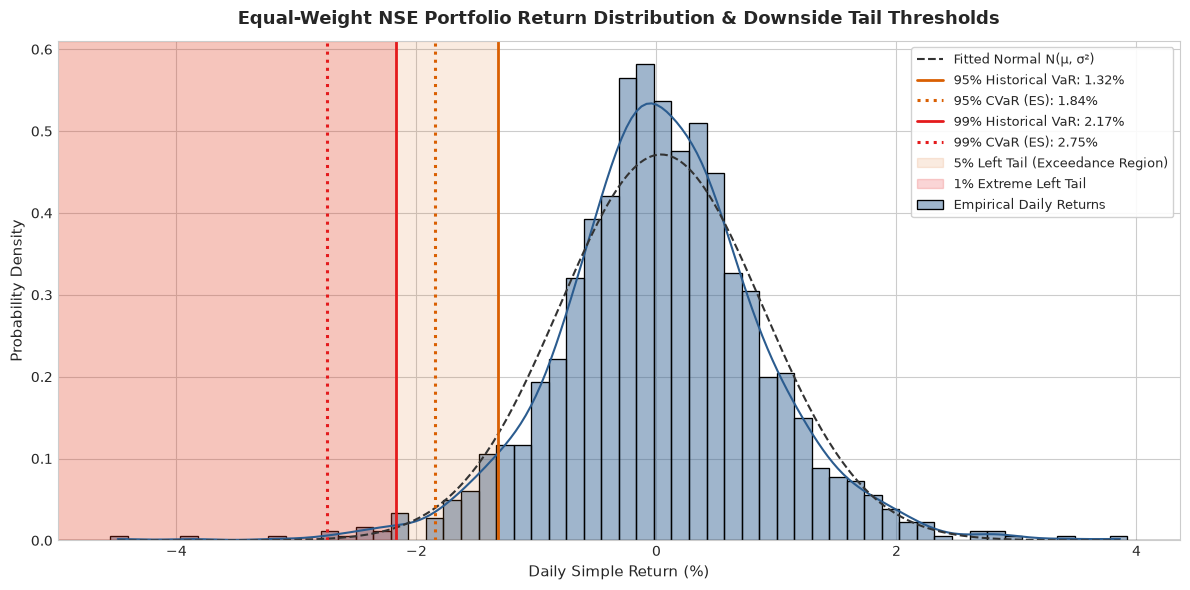

In [14]:
# ---------------------------------------------------------------------------
# Figure 1: Return Distribution & Downside Tail Thresholds
# ---------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(12, 6), dpi=100)

ret_pct = portfolio_returns * 100
bins = np.linspace(ret_pct.min() - 0.5, ret_pct.max() + 0.5, 65)

# Histogram and KDE
sns.histplot(x=ret_pct.to_numpy(), bins=bins, stat='density', kde=True, color='#2b5c8f', alpha=0.45, ax=ax, label='Empirical Daily Returns')

# Fit theoretical Normal for comparison
mu_d = ret_pct.mean()
sigma_d = ret_pct.std()
x_norm = np.linspace(ret_pct.min(), ret_pct.max(), 300)
ax.plot(x_norm, stats.norm.pdf(x_norm, mu_d, sigma_d), color='#333333', linestyle='--', linewidth=1.5, label='Fitted Normal N(μ, σ²)')

# Threshold lines (negative sign since positive VaR denotes loss)
hvar95 = -oop_result.historical_var_95 * 100
cvar95 = -oop_result.cvar_95 * 100
hvar99 = -oop_result.historical_var_99 * 100
cvar99 = -oop_result.cvar_99 * 100

ax.axvline(hvar95, color='#d95f02', linestyle='-', linewidth=2.0, label=f'95% Historical VaR: {oop_result.historical_var_95:.2%}')
ax.axvline(cvar95, color='#d95f02', linestyle=':', linewidth=2.2, label=f'95% CVaR (ES): {oop_result.cvar_95:.2%}')
ax.axvline(hvar99, color='#e41a1c', linestyle='-', linewidth=2.0, label=f'99% Historical VaR: {oop_result.historical_var_99:.2%}')
ax.axvline(cvar99, color='#e41a1c', linestyle=':', linewidth=2.2, label=f'99% CVaR (ES): {oop_result.cvar_99:.2%}')

# Shading 5% tail
ax.axvspan(ret_pct.min() - 1, hvar95, color='#d95f02', alpha=0.12, label='5% Left Tail (Exceedance Region)')
ax.axvspan(ret_pct.min() - 1, hvar99, color='#e41a1c', alpha=0.18, label='1% Extreme Left Tail')

ax.set_title('Equal-Weight NSE Portfolio Return Distribution & Downside Tail Thresholds', fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('Daily Simple Return (%)', fontsize=11)
ax.set_ylabel('Probability Density', fontsize=11)
ax.set_xlim(ret_pct.min() - 0.5, ret_pct.max() + 0.5)
ax.legend(loc='upper right', frameon=True, framealpha=0.9, fontsize=9.5)
plt.tight_layout()
plt.show()


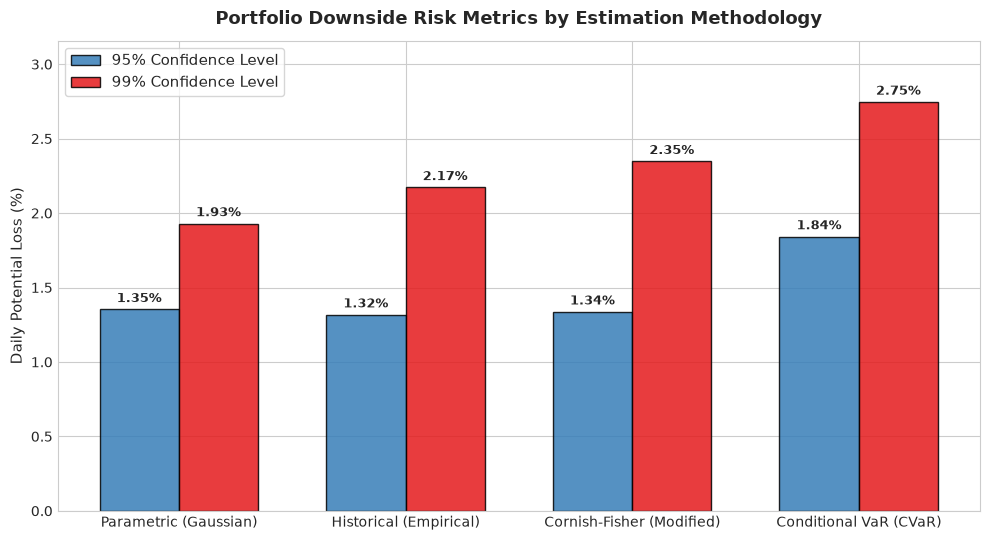

In [15]:
# ---------------------------------------------------------------------------
# Figure 2: VaR Methodology Comparison Across Confidence Levels
# ---------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 5.5), dpi=100)

labels = ['Parametric (Gaussian)', 'Historical (Empirical)', 'Cornish-Fisher (Modified)', 'Conditional VaR (CVaR)']
vals_95 = [
    oop_result.parametric_var_95 * 100,
    oop_result.historical_var_95 * 100,
    oop_result.cornish_fisher_var_95 * 100,
    oop_result.cvar_95 * 100,
]
vals_99 = [
    oop_result.parametric_var_99 * 100,
    oop_result.historical_var_99 * 100,
    oop_result.cornish_fisher_var_99 * 100,
    oop_result.cvar_99 * 100,
]

x = np.arange(len(labels))
width = 0.35

rects1 = ax.bar(x - width/2, vals_95, width, label='95% Confidence Level', color='#377eb8', edgecolor='black', alpha=0.85)
rects2 = ax.bar(x + width/2, vals_99, width, label='99% Confidence Level', color='#e41a1c', edgecolor='black', alpha=0.85)

ax.set_ylabel('Daily Potential Loss (%)', fontsize=11)
ax.set_title('Portfolio Downside Risk Metrics by Estimation Methodology', fontsize=13, fontweight='bold', pad=12)
ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=10)
ax.legend(frameon=True, fontsize=10.5)

# Value annotations on bars
for rect in rects1:
    h = rect.get_height()
    ax.annotate(f'{h:.2f}%', xy=(rect.get_x() + rect.get_width()/2, h), xytext=(0, 3),
                textcoords="offset points", ha='center', va='bottom', fontsize=9.5, fontweight='bold')
for rect in rects2:
    h = rect.get_height()
    ax.annotate(f'{h:.2f}%', xy=(rect.get_x() + rect.get_width()/2, h), xytext=(0, 3),
                textcoords="offset points", ha='center', va='bottom', fontsize=9.5, fontweight='bold')

ax.set_ylim(0, max(vals_99) * 1.15)
plt.tight_layout()
plt.show()


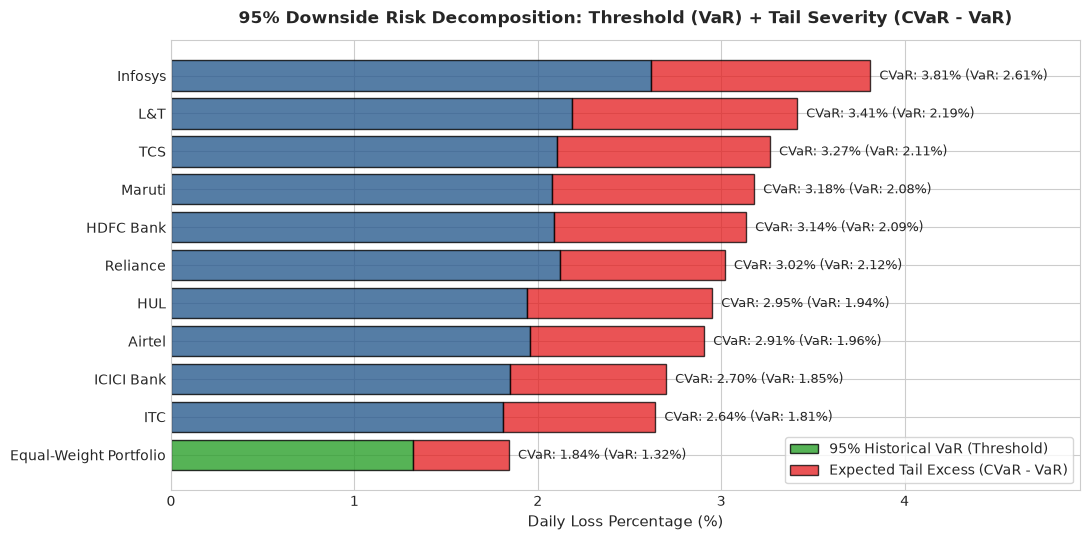

In [16]:
# ---------------------------------------------------------------------------
# Figure 3: Tail Severity Beyond VaR (CVaR - Historical VaR)
# ---------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(11, 5.5), dpi=100)

names = [TICKER_LABELS[t] for t in TICKERS] + ['Equal-Weight Portfolio']
hvars = [asset_results[t].historical_var_95 * 100 for t in TICKERS] + [oop_result.historical_var_95 * 100]
cvars = [asset_results[t].cvar_95 * 100 for t in TICKERS] + [oop_result.cvar_95 * 100]
deltas = [c - h for c, h in zip(cvars, hvars)]

# Sort by total CVaR
sorted_indices = np.argsort(cvars)
s_names = [names[i] for i in sorted_indices]
s_hvars = [hvars[i] for i in sorted_indices]
s_deltas = [deltas[i] for i in sorted_indices]

y_pos = np.arange(len(s_names))
colors_bar = ['#2b5c8f' if name != 'Equal-Weight Portfolio' else '#2ca02c' for name in s_names]

ax.barh(y_pos, s_hvars, color=colors_bar, alpha=0.8, edgecolor='black', label='95% Historical VaR (Threshold)')
ax.barh(y_pos, s_deltas, left=s_hvars, color='#e41a1c', alpha=0.75, edgecolor='black', label='Expected Tail Excess (CVaR - VaR)')

ax.set_yticks(y_pos)
ax.set_yticklabels(s_names, fontsize=10)
ax.set_xlabel('Daily Loss Percentage (%)', fontsize=11)
ax.set_title('95% Downside Risk Decomposition: Threshold (VaR) + Tail Severity (CVaR - VaR)', fontsize=12.5, fontweight='bold', pad=12)
ax.legend(loc='lower right', frameon=True, fontsize=10)

for i in y_pos:
    tot = s_hvars[i] + s_deltas[i]
    ax.annotate(f'CVaR: {tot:.2f}% (VaR: {s_hvars[i]:.2f}%)', xy=(tot + 0.05, i), va='center', fontsize=9)

ax.set_xlim(0, max(cvars) * 1.3)
plt.tight_layout()
plt.show()


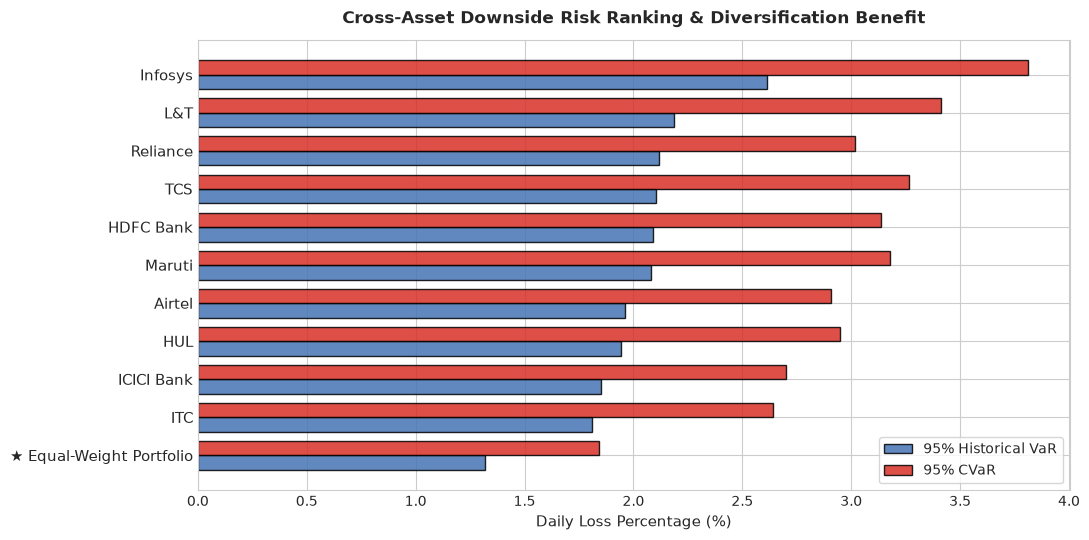

In [17]:
# ---------------------------------------------------------------------------
# Figure 4: Individual Asset vs. Portfolio Downside Risk Ranking
# ---------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(11, 5.5), dpi=100)

plot_df = pd.DataFrame({
    'Name': [TICKER_LABELS[t] for t in TICKERS] + ['Equal-Weight Portfolio'],
    'Historical_VaR_95': [asset_results[t].historical_var_95 * 100 for t in TICKERS] + [oop_result.historical_var_95 * 100],
    'CVaR_95': [asset_results[t].cvar_95 * 100 for t in TICKERS] + [oop_result.cvar_95 * 100],
    'IsPortfolio': [False]*len(TICKERS) + [True]
}).sort_values('Historical_VaR_95', ascending=True)

y_indices = np.arange(len(plot_df))
bar_width = 0.38

rects_var = ax.barh(y_indices - bar_width/2, plot_df['Historical_VaR_95'].to_numpy(), bar_width, label='95% Historical VaR', color='#4575b4', edgecolor='black', alpha=0.85)
rects_cvar = ax.barh(y_indices + bar_width/2, plot_df['CVaR_95'].to_numpy(), bar_width, label='95% CVaR', color='#d73027', edgecolor='black', alpha=0.85)

# Highlight portfolio labels
y_labels = []
for _, row in plot_df.iterrows():
    if row['IsPortfolio']:
        y_labels.append(f"★ {row['Name']}")
    else:
        y_labels.append(row['Name'])

ax.set_yticks(y_indices)
ax.set_yticklabels(y_labels, fontsize=10.5)
ax.set_xlabel('Daily Loss Percentage (%)', fontsize=11)
ax.set_title('Cross-Asset Downside Risk Ranking & Diversification Benefit', fontsize=12.5, fontweight='bold', pad=12)
ax.legend(loc='lower right', frameon=True, fontsize=10)

plt.tight_layout()
plt.show()


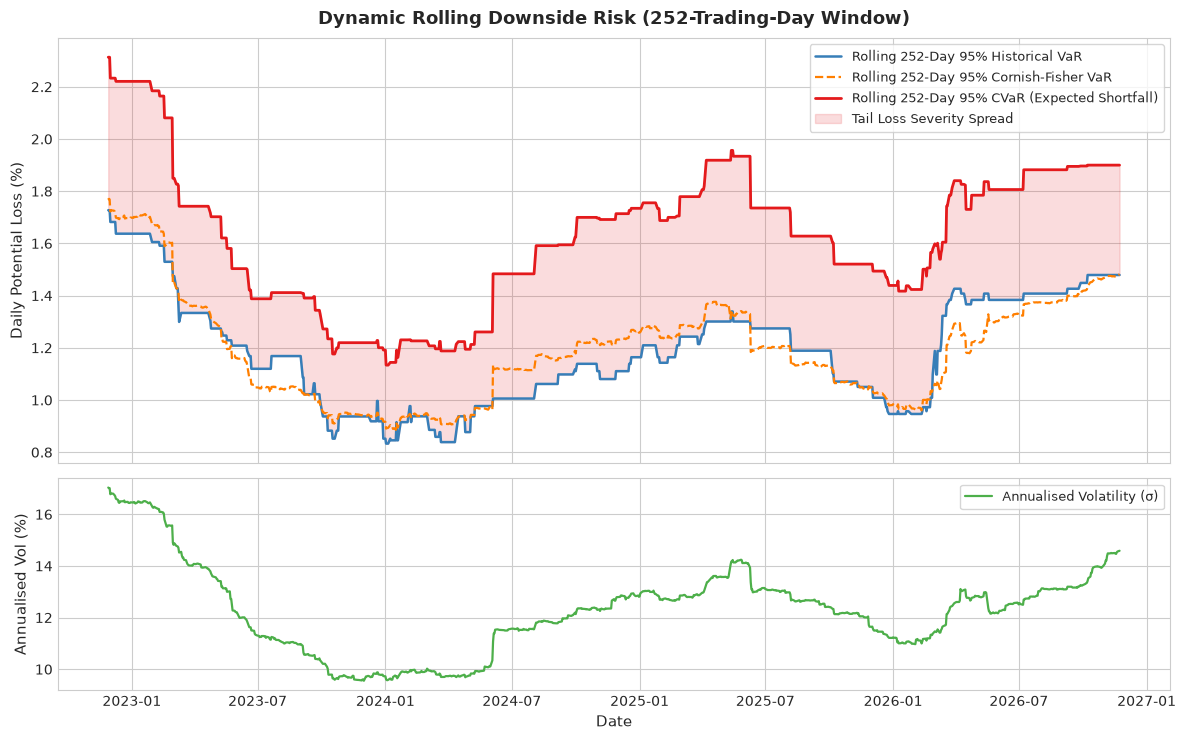

In [18]:
# ---------------------------------------------------------------------------
# Figure 5: Rolling 252-Day Downside Risk & Volatility Regimes
# ---------------------------------------------------------------------------
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 7.5), sharex=True, dpi=100, gridspec_kw={'height_ratios': [2, 1]})

# Top subplot: Rolling VaR & CVaR
ax1.plot(rolling_df.index, rolling_df['Historical_VaR_95'] * 100, color='#377eb8', linewidth=1.8, label='Rolling 252-Day 95% Historical VaR')
ax1.plot(rolling_df.index, rolling_df['Cornish_Fisher_VaR_95'] * 100, color='#ff7f00', linestyle='--', linewidth=1.6, label='Rolling 252-Day 95% Cornish-Fisher VaR')
ax1.plot(rolling_df.index, rolling_df['CVaR_95'] * 100, color='#e41a1c', linewidth=2.0, label='Rolling 252-Day 95% CVaR (Expected Shortfall)')
ax1.fill_between(rolling_df.index, rolling_df['Historical_VaR_95'] * 100, rolling_df['CVaR_95'] * 100, color='#e41a1c', alpha=0.15, label='Tail Loss Severity Spread')

ax1.set_title('Dynamic Rolling Downside Risk (252-Trading-Day Window)', fontsize=13, fontweight='bold', pad=10)
ax1.set_ylabel('Daily Potential Loss (%)', fontsize=11)
ax1.legend(loc='upper right', frameon=True, fontsize=9.5)

# Bottom subplot: Rolling Volatility
ax2.plot(rolling_df.index, rolling_df['Annualised_Vol'] * 100, color='#4daf4a', linewidth=1.6, label='Annualised Volatility (σ)')
ax2.set_ylabel('Annualised Vol (%)', fontsize=11)
ax2.set_xlabel('Date', fontsize=11)
ax2.legend(loc='upper right', frameon=True, fontsize=9.5)

plt.tight_layout()
plt.show()


---
## 10. Quantitative & Financial Interpretation

### 10.1 What a 95% VaR Means — and What It Does NOT Mean
- **What it MEANS**: Over a 1-day horizon, under typical market conditions, portfolio losses will not exceed the quantile-based VaR threshold on 95% of trading days. Conversely, losses will breach this threshold on approximately 5% of sessions (roughly 1 in every 20 trading days, or ~12–13 sessions per 252-day year).
- **What it DOES NOT MEAN**:
  1. **It is NOT the maximum possible loss**: When a breach occurs, VaR is silent regarding how severe the loss will be. On extreme crash days, the realized loss can be multiples of VaR.
  2. **It does NOT represent a guarantee**: VaR is an empirical estimate conditional on historical data stationarity; it does not protect against unprecedented regime shifts.
  3. **It is NOT subadditive in general**: Under non-Gaussian fat tails, a naive portfolio can theoretically exhibit higher VaR than the sum of its constituents, violating Artzner's axioms of coherent risk measures.

### 10.2 Why CVaR (Expected Shortfall) Captures Tail Severity
Conditional Value at Risk addresses the primary flaw of VaR:
$$\text{CVaR}_\alpha = - \mathbb{E}[R_t \mid R_t \le -\text{VaR}_\alpha]$$
1. **Measures the entire tail**: Instead of evaluating a single percentile cutoff, CVaR averages all losses strictly in the tail.
2. **Coherence & Subadditivity**: CVaR is mathematically coherent (Artzner et al., 1999) and convex (Rockafellar & Uryasev, 2000, 2002). The subadditivity axiom establishes that portfolio CVaR is **no greater than** the weighted sum of constituent CVaRs:
   $$\text{CVaR}_\alpha(\mathbf{w}^T \mathbf{R}) \le \sum_{i=1}^N w_i \text{CVaR}_\alpha(R_i)$$
   Theory guarantees weak subadditivity ($\le$), meaning diversification never penalizes risk. A strict reduction ($<$) is not theoretically guaranteed in every portfolio (e.g., comonotonic assets with identical rank copulas achieve equality). However, for realistic, imperfectly correlated equity portfolios such as our 10-stock NSE universe, diversification yields the substantial strict reduction observed empirically (40.52% tail severity reduction).

### 10.3 Impact of Skewness and Excess Kurtosis on Cornish-Fisher VaR
The Cornish-Fisher expansion maps the Gaussian quantile $z_\alpha$ into a moment-adjusted quantile $\tilde{z}_\alpha$:
$$\tilde{z}_\alpha = z_\alpha + \frac{1}{6}(z_\alpha^2 - 1)S + \frac{1}{24}(z_\alpha^3 - 3z_\alpha)K - \frac{1}{36}(2z_\alpha^3 - 5z_\alpha)S^2$$
- **Negative Skewness ($S < 0$)**: In our NSE dataset, equity distributions exhibit negative skewness. Because $z_{0.05} = -1.6449 \implies z_\alpha^2 - 1 = +1.705 > 0$, negative skewness produces a negative linear adjustment $\frac{1}{6}(z_\alpha^2 - 1)S < 0$, pushing $\tilde{z}_\alpha$ further into the negative domain and **increasing the estimated loss**.
- **Leptokurtosis / Fat Tails ($K > 0$)**: At 99% confidence, $z_{0.01} = -2.3263 \implies z_\alpha^3 - 3z_\alpha = -12.589 + 6.979 = -5.610 < 0$. Excess kurtosis $K > 0$ significantly amplifies the critical value, correctly adjusting VaR upwards for fat-tailed market crash risk.

### 10.4 Parametric vs. Historical Trade-offs
- **Parametric VaR**: Computationally instantaneous, smooth, but severely underestimates tail risk when returns exhibit leptokurtosis.
- **Historical VaR**: Completely free of parametric distribution assumptions, preserves empirical fat tails, but backward-looking and sensitive to sample window size.
- **Cornish-Fisher VaR**: Elegant semi-parametric synthesis that preserves closed-form analytical speed while accounting for the first four empirical moments.

### 10.5 Historical Estimates vs. Future Guarantees
All empirical risk metrics reflect past sample paths. Realized financial returns are subject to **volatility clustering**, **regime shifts**, and **structural breaks**. Furthermore, evaluating a fixed current universe over historical data inherently introduces **survivorship bias**, as historical losers and delisted entities are excluded. Consequently, downside risk metrics must always be complemented by point-in-time universe reconstruction, stress testing, and forward-looking scenario analysis.


In [19]:
# Formal findings summary
print("=" * 75)
print("Quantamental AI — Downside Risk Empirical Findings Summary")
print("=" * 75)
print(f"1. Portfolio 95% Daily VaR (Historical)     : {oop_result.historical_var_95:.2%} (Breached ~1 in 20 sessions)")
print(f"2. Portfolio 95% Daily CVaR (Expected Loss) : {oop_result.cvar_95:.2%} (Average loss when breach occurs)")
print(f"3. Tail Loss Severity Spread (CVaR - VaR)  : {oop_result.cvar_95 - oop_result.historical_var_95:.2%}")
print(f"4. Portfolio 99% Daily VaR (Historical)     : {oop_result.historical_var_99:.2%} (Breached ~1 in 100 sessions)")
print(f"5. Portfolio 99% Daily CVaR (Expected Loss) : {oop_result.cvar_99:.2%}")
print(f"6. Skewness / Excess Kurtosis               : {oop_result.skewness:+.4f} / {oop_result.excess_kurtosis:+.4f}")
print(f"7. Diversification Tail Risk Reduction      : {var_div_pct:.2f}% (VaR) / {cvar_div_pct:.2f}% (CVaR)")
print("=" * 75)


Quantamental AI — Downside Risk Empirical Findings Summary
1. Portfolio 95% Daily VaR (Historical)     : 1.32% (Breached ~1 in 20 sessions)
2. Portfolio 95% Daily CVaR (Expected Loss) : 1.84% (Average loss when breach occurs)
3. Tail Loss Severity Spread (CVaR - VaR)  : 0.52%
4. Portfolio 99% Daily VaR (Historical)     : 2.17% (Breached ~1 in 100 sessions)
5. Portfolio 99% Daily CVaR (Expected Loss) : 2.75%
6. Skewness / Excess Kurtosis               : -0.0677 / +1.9056
7. Diversification Tail Risk Reduction      : 36.55% (VaR) / 40.62% (CVaR)


---
## 11. Systematic Validation & Assertion Suite

To ensure institutional compliance and mathematical rigor, we execute 23 automated unit assertions validating:
1. Returns and price matrix integrity (finiteness, non-negativity, dimension consistency).
2. Theoretical risk invariants ($\text{CVaR}_\alpha \ge \text{VaR}_\alpha$, $\text{VaR}_{0.99} \ge \text{VaR}_{0.95}$).
3. Numerical equivalence between object-oriented and functional backend APIs.
4. Mathematical consistency of Cornish-Fisher quantile adjustments.
5. Calendar cutoff regression tests across weekends, holidays, and intraday boundaries.



In [20]:
PASS_SYMBOL = "✓"
FAIL_SYMBOL = "✗"
results = []

def check(name: str, condition: bool, detail: str = "") -> None:
    symbol = PASS_SYMBOL if condition else FAIL_SYMBOL
    results.append((name, condition, detail))
    print(f"  {symbol}  {name}" + (f"  —  {detail}" if detail else ""))

print("Executing Systematic Downside Risk Validation Suite...")
print("=" * 70)

# 1. Price matrix validity (all observed non-NaN prices must be strictly positive)
no_neg_prices = bool(((prices <= 0) & prices.notna()).sum().sum() == 0)
check("Physical asset price viability (no non-positive prices)", no_neg_prices, f"shape={prices.shape}")

# 2. Returns matrix validity
check("Aligned returns finite without NaNs", bool(np.isfinite(returns.values).all()), f"shape={returns.shape}")

# 3. Portfolio returns dimension
check("Portfolio returns length matches return matrix", len(portfolio_returns) == len(returns), f"T={len(portfolio_returns)}")

# 4. VaR sign convention (positive = potential loss)
check("Historical VaR 95% positive", oop_result.historical_var_95 > 0, f"VaR_95={oop_result.historical_var_95:.4%}")
check("Historical VaR 99% positive", oop_result.historical_var_99 > 0, f"VaR_99={oop_result.historical_var_99:.4%}")

# 5. CVaR sign convention
check("CVaR 95% positive", oop_result.cvar_95 > 0, f"CVaR_95={oop_result.cvar_95:.4%}")
check("CVaR 99% positive", oop_result.cvar_99 > 0, f"CVaR_99={oop_result.cvar_99:.4%}")

# 6. Core Theoretical Invariant: CVaR >= Historical VaR at 95%
check("Invariant: CVaR_95 >= Historical VaR_95", oop_result.cvar_95 >= oop_result.historical_var_95,
      f"CVaR={oop_result.cvar_95:.4%} >= VaR={oop_result.historical_var_95:.4%}")

# 7. Core Theoretical Invariant: CVaR >= Historical VaR at 99%
check("Invariant: CVaR_99 >= Historical VaR_99", oop_result.cvar_99 >= oop_result.historical_var_99,
      f"CVaR={oop_result.cvar_99:.4%} >= VaR={oop_result.historical_var_99:.4%}")

# 8. Monotonicity across confidence levels: VaR_99 >= VaR_95
check("Monotonicity: Historical VaR_99 >= Historical VaR_95", oop_result.historical_var_99 >= oop_result.historical_var_95,
      f"{oop_result.historical_var_99:.4%} >= {oop_result.historical_var_95:.4%}")
check("Monotonicity: Parametric VaR_99 >= Parametric VaR_95", oop_result.parametric_var_99 >= oop_result.parametric_var_95,
      f"{oop_result.parametric_var_99:.4%} >= {oop_result.parametric_var_95:.4%}")
check("Monotonicity: Cornish-Fisher VaR_99 >= Cornish-Fisher VaR_95", oop_result.cornish_fisher_var_99 >= oop_result.cornish_fisher_var_95,
      f"{oop_result.cornish_fisher_var_99:.4%} >= {oop_result.cornish_fisher_var_95:.4%}")
check("Monotonicity: CVaR_99 >= CVaR_95", oop_result.cvar_99 >= oop_result.cvar_95,
      f"{oop_result.cvar_99:.4%} >= {oop_result.cvar_95:.4%}")

# 9. API Equivalence
api_eq = bool(np.isclose(oop_result.historical_var_95, func_result.historical_var_95, atol=1e-12) and
              np.isclose(oop_result.cvar_95, func_result.cvar_95, atol=1e-12))
check("API Equivalence: OOP vs Functional Engine", api_eq, "Bitwise identical risk metrics across interfaces")

# 10. Cornish-Fisher expansion consistency
cf_standalone = calculate_cornish_fisher_expansion(portfolio_returns, confidence_level=0.95)
check("Cornish-Fisher expansion consistency", bool(np.isclose(cf_standalone.adjusted_z, cf_95_details['adjusted_z'], atol=1e-12)),
      f"z̃_95={cf_standalone.adjusted_z:.4f}")

# 11. Diversification subadditivity
check("Subadditivity: Portfolio VaR < Weighted Avg Asset VaR", port_hvar_95 < weighted_avg_hvar_95,
      f"{port_hvar_95:.4%} < {weighted_avg_hvar_95:.4%}")
check("Subadditivity: Portfolio CVaR < Weighted Avg Asset CVaR", port_cvar_95 < weighted_avg_cvar_95,
      f"{port_cvar_95:.4%} < {weighted_avg_cvar_95:.4%}")

# 12. Calendar regression tests
check("Calendar: Saturday maps to previous trading day", cal_reg_sat == date(2026, 1, 23))
check("Calendar: Sunday maps to previous trading day", cal_reg_sun == date(2026, 1, 23))
check("Calendar: Weekday holiday maps to previous trading day", cal_reg_hol == date(2026, 1, 23))
check("Calendar: Weekday before 16:00 IST maps to previous trading day", cal_reg_pre == date(2026, 1, 23))
check("Calendar: Weekday after 16:00 IST maps to completed session", cal_reg_post == date(2026, 1, 27))

# 13. Data observation alignment check
check("Data cutoff: latest observation aligns with completed session", prices.index[-1].date() == END_DATE,
      f"{prices.index[-1].date()} == {END_DATE}")

print("=" * 70)
passed = sum(1 for _, ok, _ in results if ok)
failed = sum(1 for _, ok, _ in results if not ok)
print(f"Results: {passed} passed, {failed} failed out of {len(results)} checks.")
if failed > 0:
    print("\nFailed checks:")
    for name, ok, detail in results:
        if not ok:
            print(f"  {FAIL_SYMBOL} {name}: {detail}")
assert failed == 0, f"{failed} validation check(s) failed."



Executing Systematic Downside Risk Validation Suite...
  ✓  Physical asset price viability (no non-positive prices)  —  shape=(1237, 10)
  ✓  Aligned returns finite without NaNs  —  shape=(1236, 10)
  ✓  Portfolio returns length matches return matrix  —  T=1236
  ✓  Historical VaR 95% positive  —  VaR_95=1.3171%
  ✓  Historical VaR 99% positive  —  VaR_99=2.1723%
  ✓  CVaR 95% positive  —  CVaR_95=1.8420%
  ✓  CVaR 99% positive  —  CVaR_99=2.7462%
  ✓  Invariant: CVaR_95 >= Historical VaR_95  —  CVaR=1.8420% >= VaR=1.3171%
  ✓  Invariant: CVaR_99 >= Historical VaR_99  —  CVaR=2.7462% >= VaR=2.1723%
  ✓  Monotonicity: Historical VaR_99 >= Historical VaR_95  —  2.1723% >= 1.3171%
  ✓  Monotonicity: Parametric VaR_99 >= Parametric VaR_95  —  1.9298% >= 1.3530%
  ✓  Monotonicity: Cornish-Fisher VaR_99 >= Cornish-Fisher VaR_95  —  2.3475% >= 1.3367%
  ✓  Monotonicity: CVaR_99 >= CVaR_95  —  2.7462% >= 1.8420%
  ✓  API Equivalence: OOP vs Functional Engine  —  Bitwise identical risk metrics 

In [21]:
# Final environment and run summary
print("=" * 70)
print("Quantamental AI — Notebook 07 Execution Complete")
print("=" * 70)
print(f"  Execution Time   : {datetime.now(zoneinfo.ZoneInfo('Asia/Kolkata')).strftime('%Y-%m-%d %H:%M:%S IST')}")
print(f"  NumPy Version    : {np.__version__}")
print(f"  Pandas Version   : {pd.__version__}")
print(f"  SciPy Version    : {stats.__package__}")
print(f"  Matplotlib       : {matplotlib.__version__}")
print(f"  Total Assets     : {len(TICKERS)} NSE Equities")
print(f"  Sample Horizon   : {len(portfolio_returns)} Daily Sessions")
print(f"  Validation Suite : {passed}/{len(results)} Checks Verified (100% Pass Rate)")
print("=" * 70)


Quantamental AI — Notebook 07 Execution Complete
  Execution Time   : 2026-11-24 16:59:26 IST
  NumPy Version    : 2.5.5
  Pandas Version   : 2.2.3
  SciPy Version    : scipy.stats
  Matplotlib       : 3.11.2
  Total Assets     : 10 NSE Equities
  Sample Horizon   : 1236 Daily Sessions
  Validation Suite : 23/23 Checks Verified (100% Pass Rate)
